# Workout LGD: cash flows, discounting and incomplete workouts

**Question:** What share of a defaulted loan is lost once its recoveries are discounted, and how far is the charge-off indicator that case C08 builds from the SBA 7(a) small-business loans from that workout measure?

- **Level:** 1, Fundamentals
- **Prerequisites:** notebooks 01 and 02 of topic 01 (the engine and an artifact)
- **Reading time:** about 35 minutes

## Objectives

By the end of this notebook you can:

- write the realised LGD of a defaulted loan as one minus the discounted net recoveries over the exposure at default, and compute it by hand and with `workout_lgd`;
- say what the discount rate does to an LGD, and build the EU-style rate with `eba_discount_rate`;
- flag an LGD below 0 or above 1 with `range_flag`, and explain why it is kept and never clipped;
- say why leaving the open workouts out biases the LGD down, and treat them explicitly with `resolve_incomplete` and `closed_before`;
- read the LGD of case C08, a charge-off proxy on the SBA 7(a) small-business loans, and say exactly how it differs from a workout LGD.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.1.0 numpy==2.4.6 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you.

In [1]:
# Import the tools and print their versions, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from riskvalidation.lgd_ead import workout

for name in ("riskvalidation", "numpy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 1.0.1
numpy 2.4.6
matplotlib 3.11.2


## Data

One committed artifact, `data/derived/C08/dc-2007-08.json`, the variant of case C08 for the defaults of 2007 and 2008. C08 is built on the public SBA 7(a) loan file (small-business loans, a mirror-allowed source), because Freddie Mac's loss fields stay derived-only and offline in this product. The file has **no recovery cash flows**: it records the amount charged off and the amount approved. So the LGD of C08 is a *proxy*, and the artifact says so in `outputs.lgd_proxy`.

That is why this notebook has two halves. The first half teaches the workout LGD on a small worked example whose cash flows are written in the notebook (four invented loans, labelled as such), because the engine's `workout` functions need cash flows. The second half reads the committed C08 artifact and shows what a charge-off proxy is, what it hides and how the engine flags it. The artifact was baked by an older engine than the one installed here, so the next cell prints the baked version.

In [2]:
# Open the committed artifact of case C08 and print the engine version that baked it
ROOT = Path("../../..").resolve()
c08 = json.loads((ROOT / "data" / "derived" / "C08" / "dc-2007-08.json").read_text(encoding="utf-8"))
out = c08["outputs"]
print("case:", c08["case_id"], "| variant:", c08["variant_id"], "|", out["cohort"]["label"]["en"])
print("baked by riskvalidation:", c08["provenance"]["riskvalidation_version"])
print("installed:", rv.__version__)

case: C08 | variant: dc-2007-08 | Defaults 2007-08
baked by riskvalidation: 1.0.1
installed: 1.0.1


## Method

### Step 1: the realised LGD of one loan

For a defaulted loan $i$ with exposure at default $EAD_i$, the engine's `workout` module computes

$$LGD_i = 1 - \frac{\sum_t (R_t - C_t - A_t)\,(1 + r_i)^{-t}}{EAD_i}$$

where $R_t$ is a recovery received at time $t$ (in years since the default date), $C_t$ the direct and indirect costs paid at $t$, $A_t$ an additional drawing after the default, and $r_i$ the discount rate. The sum is the present value, at the default date, of everything the bank got back net of what it paid; one minus its share of the exposure is the share lost. (Source: the docstring of `riskvalidation.lgd_ead.workout` at release 0.8.1; the rule for the discount rate is described in step 2.)

Below, four invented loans. Each row of the arrays is a loan and each column a cash-flow date. The first cell writes them, and then computes loan A **by hand**, one flow at a time, so every intermediate is on screen.

In [3]:
# Four invented defaulted loans (A to D), and loan A by hand at an 8% rate, one flow at a time
loans = ["A", "B", "C", "D"]
ead = np.array([100_000.0, 50_000.0, 80_000.0, 20_000.0])
times = np.array([[0.5, 1.0, 2.0], [0.25, 1.0, 1.5], [1.0, 2.0, 3.0], [0.5, 1.0, 1.5]])
recoveries = np.array([[30_000, 40_000, 20_000], [10_000, 15_000, 10_000],
                       [5_000, 8_000, 2_000], [14_000, 9_000, 4_000]], dtype=float)
costs = np.array([[2_000, 2_000, 1_000], [3_000, 1_000, 500],
                  [9_000, 7_000, 6_000], [500, 200, 100]], dtype=float)
drawings = np.zeros_like(recoveries)

rate = 0.08
net = recoveries[0] - costs[0] - drawings[0]
factor = (1 + rate) ** (-times[0])
present = net * factor
fmt = "flow {}: t={:<4} net={:>8,.0f} factor={:.4f} present value={:>9,.2f}"
for k in range(3):
    print(fmt.format(k + 1, times[0, k], net[k], factor[k], present[k]))
print(f"sum of present values: {present.sum():,.2f} | EAD: {ead[0]:,.0f}")
print(f"LGD = 1 - {present.sum():,.2f} / {ead[0]:,.0f} = {1 - present.sum() / ead[0]:.4f}")

flow 1: t=0.5  net=  28,000 factor=0.9623 present value=26,943.01
flow 2: t=1.0  net=  38,000 factor=0.9259 present value=35,185.19
flow 3: t=2.0  net=  19,000 factor=0.8573 present value=16,289.44
sum of present values: 78,417.64 | EAD: 100,000
LGD = 1 - 78,417.64 / 100,000 = 0.2158


The same number comes out of `workout_lgd`, which does the whole table at once and rejects bad input (a non-positive EAD, a negative flow, a time at or before the default date). The next cell calls it for the four loans at the same rate and checks loan A against the hand calculation.

In [4]:
# Run the engine's workout_lgd on the four loans at the same rate
lgd = workout.workout_lgd(ead, times, recoveries, costs, drawings, rate)
for name, value in zip(loans, lgd):
    print(f"loan {name}: LGD = {value:.4f}")
print(f"loan A by hand: {1 - present.sum() / ead[0]:.4f}")

loan A: LGD = 0.2158
loan B: LGD = 0.4341
loan C: LGD = 1.0753
loan D: LGD = -0.2307
loan A by hand: 0.2158


### Step 2: the discount rate

The rate matters: a recovery two years away is worth less at the default date than one that arrives next month. The EU convention is an interbank rate at the default date plus an add-on; `eba_discount_rate(interbank_rate, add_on=0.05)` returns that sum. The paragraph number of the EBA guideline behind the 5% add-on is marked UNVERIFIED in the engine itself, so this notebook states the convention and does not cite a paragraph. A caller may pass any other rate to `workout_lgd`.

The next cell builds the rate for an interbank rate of 3% and recomputes the four LGDs on a grid of rates from 0% to 15%. The direction to expect: a higher rate shrinks the present value of the net recoveries and raises the LGD of a loan with positive net flows; loan C, whose net flows are negative, is the exception.

EU-style rate (3% interbank + 5% add-on): 0.08
rate 0.00: A  0.1500  B  0.3900  C  1.0875  D -0.3100
rate 0.08: A  0.2158  B  0.4341  C  1.0753  D -0.2307
rate 0.12: A  0.2447  B  0.4536  C  1.0703  D -0.1952


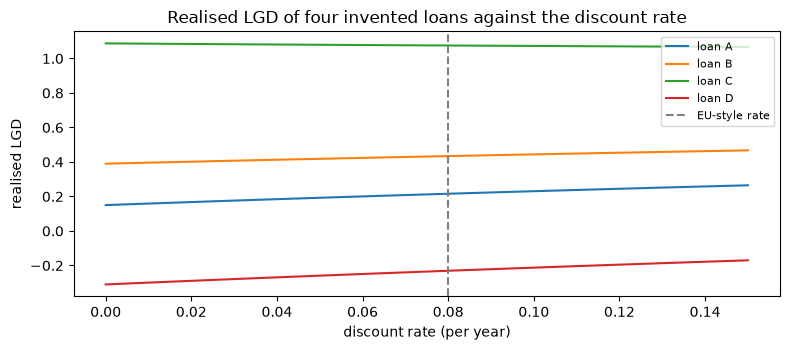

In [5]:
# Build the EU-style rate, recompute the four LGDs on a grid of rates and draw them
eu_rate = workout.eba_discount_rate(0.03)
print(f"EU-style rate (3% interbank + 5% add-on): {eu_rate:.2f}")
grid = np.linspace(0.0, 0.15, 31)
curves = np.array([workout.workout_lgd(ead, times, recoveries, costs, drawings, r) for r in grid])
for r in (0.0, eu_rate, 0.12):
    row = workout.workout_lgd(ead, times, recoveries, costs, drawings, r)
    print(f"rate {r:.2f}: " + "  ".join(f"{n} {v:7.4f}" for n, v in zip(loans, row)))

fig, ax = plt.subplots(figsize=(8, 3.6))
for j, name in enumerate(loans):
    ax.plot(grid, curves[:, j], label=f"loan {name}")
ax.axvline(eu_rate, color="grey", linestyle="--", label="EU-style rate")
ax.set_xlabel("discount rate (per year)")
ax.set_ylabel("realised LGD")
ax.set_title("Realised LGD of four invented loans against the discount rate")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

The lines of loans A, B and D climb with the rate, because their recoveries arrive after the default date and every year of waiting is worth less; at 8%, the dashed line, loan A loses 0.2158 of its exposure against 0.1500 with no discounting. Loan C is the exception: its costs exceed its recoveries, so the net flows it pays out are the ones discounted, and a higher rate makes the loss smaller, from 1.0875 down to 1.0703 at 12%. The slopes are modest for this book because the cash flows fall within three years; a workout of eight years would tilt the lines much more. The point for a validator is that the LGD is not a property of the loan alone: it moves with a rate that must be stated.

### Step 3: an LGD outside [0, 1] is kept and flagged

Loan C pays more in costs than it recovers, so its LGD is above 1. Loan D recovers more than its exposure (a collateral sale above book value), so its LGD is below 0. Real portfolios have both. The engine never clips a realised LGD: clipping would hide exactly the cases a validator needs to see, and would move the mean. `range_flag` labels every value `below-zero`, `above-one` or `in-range`, so the count of each can be reported beside the distribution.

In [6]:
# Flag each LGD and compare the mean of the raw values with the mean after clipping to [0, 1]
flags = workout.range_flag(lgd)
label = {"below-zero": "below zero", "in-range": "in range", "above-one": "above one"}
for name, value, flag in zip(loans, lgd, flags):
    print(f"loan {name}: LGD = {value:8.4f} | {label[str(flag)]}")
print(f"mean of the raw LGDs: {lgd.mean():.4f}")
print(f"mean after clipping to [0, 1]: {np.clip(lgd, 0, 1).mean():.4f}")

loan A: LGD =   0.2158 | in range
loan B: LGD =   0.4341 | in range
loan C: LGD =   1.0753 | above one
loan D: LGD =  -0.2307 | below zero
mean of the raw LGDs: 0.3736
mean after clipping to [0, 1]: 0.4125


### Step 4: incomplete workouts

A loan that defaulted recently is still being worked out: its recoveries are not all in. If a portfolio's LGD is computed only on the *closed* workouts, the slow ones, which tend to be the worst, are missing, and the LGD is biased down. The engine makes the treatment an explicit argument: `resolve_incomplete(lgd, complete, treatment)` with `treatment` equal to `"excluded"` (drop the open ones and count them) or `"projected"` (replace them by a projection supplied by the caller). It returns how many were excluded or projected, so the choice is never silent.

The next cell invents ten workouts: six closed, four open, with a projection for each open one (invented too), and shows both treatments.

In [7]:
# Two treatments of ten invented workouts, six closed and four open
lgd_ten = np.array([0.30, 0.45, 0.55, 0.60, 0.40, 0.65, np.nan, np.nan, np.nan, np.nan])
complete = np.array([True] * 6 + [False] * 4)
projected = np.array([np.nan] * 6 + [0.80, 0.85, 0.75, 0.90])
name_of = {"excluded": "excluded", "projected": "projected"}
for treatment in ("excluded", "projected"):
    extra = projected if treatment == "projected" else None
    res = workout.resolve_incomplete(lgd_ten, complete, treatment, extra)
    print(f"{name_of[treatment]:11s}: kept={res.lgd.size} excluded={res.n_excluded}"
          f" projected={res.n_projected} mean LGD={res.lgd.mean():.4f}")

excluded   : kept=6 excluded=4 projected=0 mean LGD=0.4917
projected  : kept=10 excluded=0 projected=4 mean LGD=0.6250


`closed_before(close_dates, cutoff)` is the companion rule for a training set: a workout counts only if it closed strictly before the cutoff, and an open workout (a missing close date) never does. The cell below applies it to five close dates with the cutoff that case C08 used, read from its artifact.

In [8]:
# Apply the training-set rule with the cutoff of C08 to five close dates
cutoff = out["training"]["cutoff_date"]
close_dates = np.array(["2005-06-30", "2006-12-30", "2006-12-31", "2007-03-15", "NaT"], dtype="datetime64[D]")
print("cutoff of C08:", cutoff)
for date, ok in zip(close_dates, workout.closed_before(close_dates, cutoff)):
    print(f"closed on {date}: enters training = {'yes' if ok else 'no'}")

cutoff of C08: 2006-12-31
closed on 2005-06-30: enters training = yes
closed on 2006-12-30: enters training = yes
closed on 2006-12-31: enters training = no
closed on 2007-03-15: enters training = no
closed on NaT: enters training = no


### Step 5: the committed LGD of case C08

Now the real artifact. Its `lgd_proxy` block states that the target is the gross charge-off amount over the gross approved amount, that no recovery cash flows exist in the public file and that the bias runs downward. The cell computes, from the artifact's own totals, the two means that matter: the mean of the loan-level indicator (every loan counts once) and the pooled ratio of the total charged off to the total approved (every dollar counts once). They differ when loans of different sizes lose different shares. It also counts the loans at exactly 1 and above 1.

In [9]:
# Read the stated bias of the charge-off indicator and compute the two means and the masses at 1 and above 1
block = out["lgd_proxy"]
dist = out["lgd_distribution"]
exposure = out["exposure"]
pooled = exposure["gross_charge_off_total"] / exposure["gross_approval_total"]
print("recovery cash flows available:", block["recovery_cash_flows_available"])
print("stated bias direction:", block["bias_direction"])
print(f"defaults in the cohort: {dist['n']:,}")
print(f"mean of the loan-level indicator: {dist['mean']['value']:.4f}")
print(f"median: {dist['median']['value']:.4f}")
print(f"pooled ratio, charged off over approved: {pooled:.4f} ({exposure['currency']})")
print(f"exactly 1: {dist['mass_at_one']['n']:,} ({dist['mass_at_one']['share']:.2%})")
print(f"above 1: {dist['n_above_one']:,} ({dist['share_above_one']:.2%}) | below 0: {dist['n_below_zero']}")

recovery cash flows available: False
stated bias direction: downward
defaults in the cohort: 25,299
mean of the loan-level indicator: 0.8178
median: 0.8901
pooled ratio, charged off over approved: 0.6478 (USD)
exactly 1: 3,204 (12.66%)
above 1: 593 (2.34%) | below 0: 0


The mean of the loan-level indicator is well above the pooled ratio, and a share of the loans sit exactly at 1 or above it: the charge-off equalled or exceeded the approved amount, which capitalised interest and fees can cause. Nothing here has been discounted, since there are no cash flows to discount: the artifact records the discount convention as `none-proxy`. The next cell draws the distribution inside [0, 1] from the artifact's ten bins, and prints how the open workouts of the training set were treated.

training defaults: 48,833
open workouts excluded and counted: 7,388


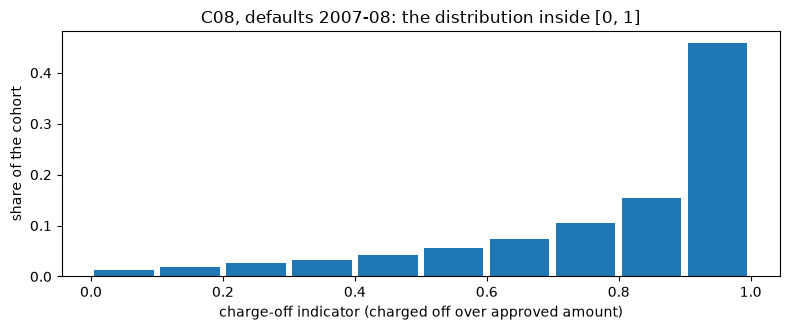

In [10]:
# Draw the distribution inside [0, 1] from the ten bins and count the open workouts left out of training
bins = dist["bins"]
centres = [(x["lower"] + x["upper"]) / 2 for x in bins]
print("training defaults:", f"{out['training']['n_defaults']:,}")
print("open workouts excluded and counted:", f"{out['training']['n_open_workouts_excluded']:,}")

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.bar(centres, [x["share"] for x in bins], width=0.09, color="tab:blue")
ax.set_xlabel("charge-off indicator (charged off over approved amount)")
ax.set_ylabel("share of the cohort")
ax.set_title("C08, defaults 2007-08: the distribution inside [0, 1]")
fig.tight_layout()
plt.show()

Reading the bars: the mass is not spread evenly but leans to the right, with the largest bars in the last bins, so most small-business defaults of 2007-08 were charged off for most of the approved amount. Together with the 12.66% of loans at exactly 1 and the 2.34% above it, which sit outside the ten bins, this is the cohort mean of 0.8178 in picture form. What the figure cannot say is how much the lender recovered afterwards, because the public file stops at the charge-off; that is the downward-bias statement the artifact makes, and it is why the 7,388 open workouts excluded from training matter: they are the slow cases the closed ones do not represent.

The engine's `lgd_distribution(lgd, edges)` builds the same kind of table from loan-level values: the counts per bin inside [0, 1], the values outside counted apart and the exact masses at 0 and 1. The artifact holds its result, not the loan-level values (the SBA file is a third-party dataset that is not committed), so the last cell runs the function on the four invented LGDs of step 1 with the artifact's own bin edges, to show what it returns and how it keeps the values outside [0, 1] out of the bins.

In [11]:
# Run lgd_distribution on the four invented LGDs with the bin edges of the artifact
edges = np.array([bins[0]["lower"]] + [x["upper"] for x in bins])
table = workout.lgd_distribution(lgd, edges)
print("edges:", edges)
print("counts per bin:", table.counts)
print(f"n={table.n} | below 0={table.n_below_zero} | above 1={table.n_above_one}")
print(f"mass at 0={table.mass_zero} | mass at 1={table.mass_one}")

edges: [0.  0.1 0.2 0.3 0.4 0.5 0.6 0.7 0.8 0.9 1. ]
counts per bin: [0 0 1 0 1 0 0 0 0 0]
n=4 | below 0=1 | above 1=1
mass at 0=0 | mass at 1=0


## Results

**Answer:** Discounted at 8%, the recoveries of the invented loan A are worth 78,417.64 against an exposure of 100,000, so it loses 0.2158 of it, and the same arithmetic gives -0.2307 for the over-recovered loan D and 1.0753 for the cost-heavy loan C. The charge-off indicator of C08 is a different object: with no cash flows to discount, the 25,299 defaults of 2007-08 have a loan-level mean of 0.8178 and a pooled ratio of 0.6478, so it measures what was written off, not the loss after recoveries, and it cannot stand for a workout LGD.

- **The workout LGD is a present value.** Loan A has an LGD of 0.2158: the recoveries, net of costs and discounted at 8%, are worth 78,417.64 against an exposure of 100,000 (the hand calculation and `workout_lgd` agree). In the step 2 table a higher rate raises the LGD of loans A, B and D, and lowers the LGD of loan C, whose net flows are negative, so that discounting shrinks what it pays out.
- **Outside [0, 1] is information.** The cost-heavy loan C is at 1.0753 and the over-recovered loan D at -0.2307; clipping them moves the mean of the four from 0.3736 to 0.4125.
- **Open workouts must be treated, and the treatment is a number.** Excluding the four open workouts gives a mean LGD of 0.4917; projecting them gives 0.6250. That gap is the downward bias the research warns about, and `resolve_incomplete` returns the counts so that the choice is visible. The four workouts are invented, so the size of the gap says nothing about a real portfolio.
- **C08 is a proxy, not a workout LGD.** There are no recovery cash flows, nothing is discounted, and the artifact states its bias direction. For the 2007-08 cohort (25,299 defaults) the mean of the loan-level proxy is 0.8178 while the pooled ratio of the total charged off to the total approved is 0.6478. 3,204 loans (12.66%) sit exactly at 1 and 593 (2.34%) are above 1, kept and flagged; none is below 0.

What the notebook does not do: it does not estimate a workout LGD for a real portfolio, since the committed data has no cash flows. The four loans of steps 1 to 4 are invented to show the arithmetic, and their numbers say nothing about any lender. The next notebook turns to the other half of the exposure, the exposure at default and the credit conversion factor.

## Summary

- Realised LGD is one minus the discounted net recoveries over the EAD; `workout_lgd` computes it for many loans at once and rejects inconsistent input.
- The discount rate is a stated convention (`eba_discount_rate` is the EU-style sum of an interbank rate and an add-on), and a higher rate raises the LGD of a loan whose net flows are positive.
- A realised LGD outside [0, 1] is kept and flagged with `range_flag`, never clipped.
- Open workouts bias the LGD down if they are simply left out; `resolve_incomplete` makes the treatment explicit and `closed_before` states the training-set rule.
- The committed C08 LGD is a charge-off proxy on public small-business data: no cash flows, no discounting, a stated bias direction, and values above 1 kept and flagged.

**What to try next.** Change the rate in step 1 and the costs of loan C and watch the LGDs move; then continue with notebook 02, which does the same for the exposure at default.

## References

- BCBS, Basel Framework, CRE32 (internal ratings-based approach: calculation of risk-weighted assets for credit risk; the LGD input floors and the treatment of LGD in the advanced approach). https://www.bis.org/committees/bcbs/basel-framework/standard/cre/32/inforce/2023-01-01/published/2020-03-27
- BCBS (2017), Basel III: Finalising post-crisis reforms (d424), the LGD input floors for the advanced approach. https://www.bis.org/bcbs/publ/d424.htm
- The engine's own documentation of the module: `riskvalidation.lgd_ead.workout` (the formula, the range flags and the treatment of incomplete workouts, read from its docstrings at release 0.8.1).
- This repository: `docs/design/SDD.md` (case C08, the SBA 7(a) charge-off twin) and `data/derived/C08/dc-2007-08.json` (`outputs.lgd_proxy`).